## 6. 一般化線形モデル
### 6.8 適用例
#### 図6.1

In [33]:
x <- c(1.691, 1.724, 1.755, 1.784, 1.811, 1.837, 1.861, 1.884)
d <- c(4, 10, 19, 31, 52, 53, 60, 60)
n <- c(59, 60, 62, 56, 63, 59, 62, 60)
r <- n - d
dose <- data.frame(x, n, d, r)
out <- glm(cbind(d, r) ~ x, family = "binomial", data = dose)
Pres <- residuals(out, type = "pearson") # Pearson residuals
e <- n*out$fitted.value # expeceted number of deaths

In [34]:
summary(out)


Call:
glm(formula = cbind(d, r) ~ x, family = "binomial", data = dose)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)    
(Intercept)  -64.768      5.514  -11.75   <2e-16 ***
x             36.531      3.099   11.79   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 295.5705  on 7  degrees of freedom
Residual deviance:   4.0723  on 6  degrees of freedom
AIC: 34.335

Number of Fisher Scoring iterations: 4


In [35]:
print(1 - pchisq(out$deviance, df = out$df.residual))

[1] 0.6668909


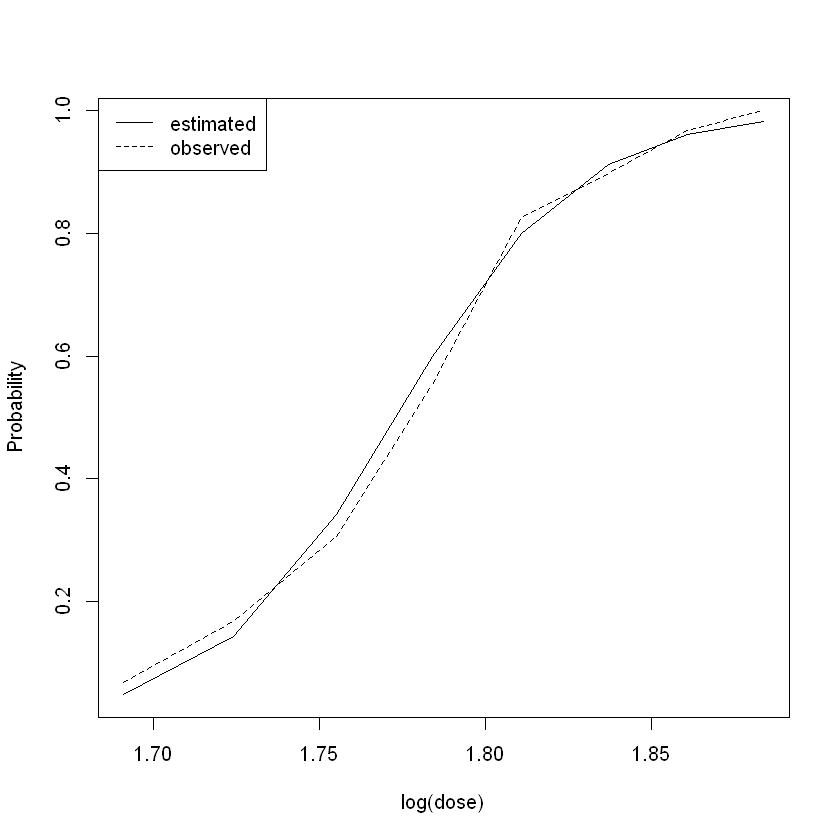

In [36]:
par(bg = "white")
plot(x, e/n, type = "l", xlab = "log(dose)", ylab = "Probability")
lines(x, d/n, lty = 2)
legend("topleft", legend = c("estimated", "observed"), lty = c(1, 2))

### 問題
#### 問題6.4

In [37]:
x <- c(1.691, 1.724, 1.755, 1.784, 1.811, 1.837, 1.861, 1.884)
d <- c(4, 10, 19, 31, 52, 53, 60, 60)
n <- c(59, 60, 62, 56, 63, 59, 62, 60)
r <- n - d
dose <- data.frame(x, n, d, r)
out <- glm(cbind(d, r) ~ x, family="binomial", data=dose)

In [38]:
X <- c()
Y <- c()

for (i in 1:8) {
  X <- c(X, rep(x[i], n[i]))
  Y <- c(Y, rep(0, n[i] - d[i]), rep(1, d[i]))
}

glm(Y ~ X, family = binomial(link = logit), data = dose)


Call:  glm(formula = Y ~ X, family = binomial(link = logit), data = dose)

Coefficients:
(Intercept)            X  
     -64.77        36.53  

Degrees of Freedom: 480 Total (i.e. Null);  479 Residual
Null Deviance:	    647.1 
Residual Deviance: 355.6 	AIC: 359.6

Fisherスコア法(6.27)で計算

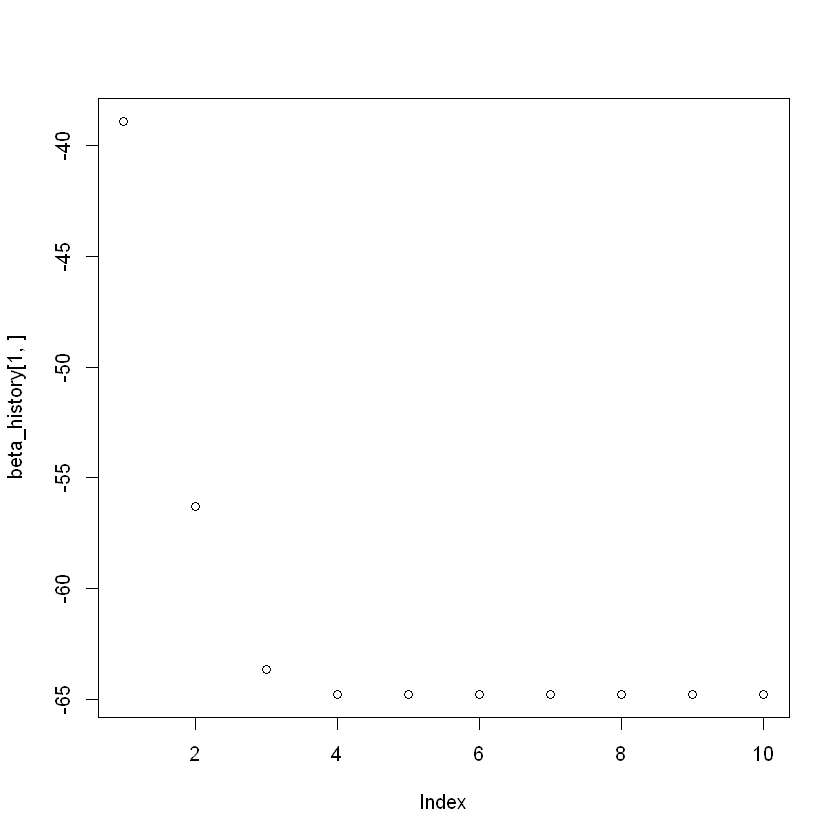

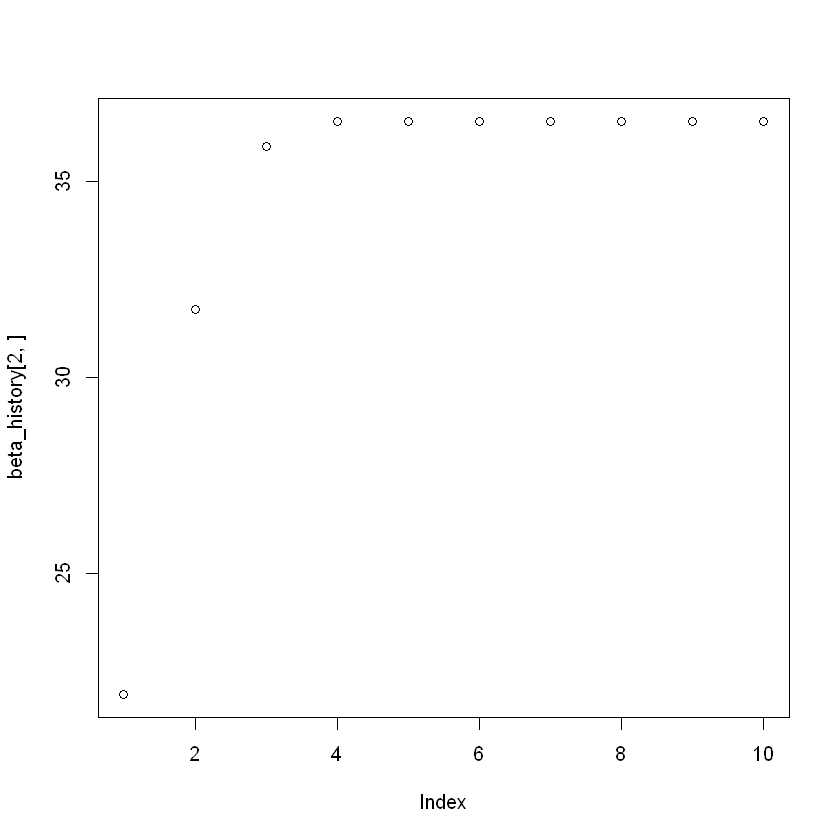

In [39]:
beta = c(0, 0)
beta_history = c()

Xc <- cbind(1, X)

for (k in 1:10) {
  theta <- Xc %*% beta
  mu <- 1 / (1 + exp(-theta))
  dg <- 1 / (mu*(1-mu))
  ddb <- exp(theta) / (1+exp(theta))^2
  w <- 1 / (ddb*dg^2)

  M <- matrix(0, nrow = 2, ncol = 2)
  N <- matrix(0, nrow = 2, ncol = 1)
  for (i in 1:length(X)) {
    M <- M + w[i]*Xc[i, ] %*% t(Xc[i, ])
    N <- N + w[i]*dg[i]*(Y[i] - mu[i])*Xc[i, ]
  }

  beta <- beta + solve(M) %*% N

  beta_history <- cbind(beta_history, beta)
}

par(bg = "white")
plot(beta_history[1, ]); plot(beta_history[2, ])